In [11]:
import duckdb

import matplotlib.pyplot as plt
from pathlib import Path

In [12]:
db = duckdb.connect("db/duckdb_trains.db")

Put stations data into `stations` table

In [13]:
stations_path = "data/stations-2023-09.csv"

db.sql(f"""
CREATE OR REPLACE TABLE stations AS
FROM read_csv('{stations_path}')
""")

In [14]:
db.sql("""
FROM stations
ORDER BY id
LIMIT 5
""")

┌───────┬─────────┬─────────┬────────────┬─────────────┬────────────────────┬────────────────────┬─────────┬───────────────────────────┬─────────────────┬─────────────────┐
│  id   │  code   │   uic   │ name_short │ name_medium │     name_long      │        slug        │ country │           type            │     geo_lat     │     geo_lng     │
│ int64 │ varchar │  int64  │  varchar   │   varchar   │      varchar       │      varchar       │ varchar │          varchar          │     double      │     double      │
├───────┼─────────┼─────────┼────────────┼─────────────┼────────────────────┼────────────────────┼─────────┼───────────────────────────┼─────────────────┼─────────────────┤
│     5 │ AC      │ 8400047 │ Abcoude    │ Abcoude     │ Abcoude            │ abcoude            │ NL      │ stoptreinstation          │         52.2785 │           4.977 │
│     6 │ AH      │ 8400071 │ Arnhem C   │ Arnhem C.   │ Arnhem Centraal    │ arnhem-centraal    │ NL      │ knooppuntIntercitystation 

Create tables `distances` and `distances_long`

In [15]:
tarriff_distances_path = "data/tariff-distances-2022-01.csv"

db.sql(f"""
CREATE OR REPLACE TABLE distances AS
FROM read_csv(
    '{tarriff_distances_path}',
    nullstr = 'XXX'
)
""")

In [16]:
db.sql("""
SELECT #1, #2, #3, #4
FROM distances
LIMIT 5
""")

┌─────────┬───────┬───────┬───────┐
│ Station │  AC   │  AH   │  AHP  │
│ varchar │ int64 │ int64 │ int64 │
├─────────┼───────┼───────┼───────┤
│ AC      │  NULL │    82 │    83 │
│ AH      │    82 │  NULL │     1 │
│ AHP     │    83 │     1 │  NULL │
│ AHPR    │    85 │     3 │     2 │
│ AHZ     │    90 │     8 │     9 │
└─────────┴───────┴───────┴───────┘

In [17]:
db.sql("""
FROM (DESCRIBE distances)
LIMIT 5;
""")

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ Station     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ AC          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AH          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AHP         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AHPR        │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

In [18]:
db.sql("""
CREATE OR REPLACE TABLE distances_long AS
UNPIVOT distances
ON COLUMNS (* EXCLUDE station)
INTO NAME other_station VALUE distance;
""")

In [19]:
db.sql("""
FROM distances_long
LIMIT 5
""")

┌─────────┬───────────────┬──────────┐
│ Station │ other_station │ distance │
│ varchar │    varchar    │  int64   │
├─────────┼───────────────┼──────────┤
│ AC      │ AH            │       82 │
│ AC      │ AHP           │       83 │
│ AC      │ AHPR          │       85 │
│ AC      │ AHZ           │       90 │
│ AC      │ AKL           │       71 │
└─────────┴───────────────┴──────────┘

Put train disruptions into `disruptions` table in the Postgres database

In [20]:
db.sql("""
INSTALL postgres; LOAD postgres
""")

conn_string = "host=localhost user=postgres password=postgres dbname=postgres"

db.sql(f"""
ATTACH IF NOT EXISTS '{conn_string}' AS postgres_db (TYPE postgres)
""")

In [21]:
disruptions_paths = [
    f"data/disruptions-{year}.csv" for year in range(2011, 2024)
]  # 2011-2023

db.sql(f"""
CREATE OR REPLACE TABLE postgres_db.disruptions AS
FROM read_csv({disruptions_paths})
""")

In [22]:
db.sql("""
SELECT #1, #2, #3, #4, #5
FROM postgres_db.disruptions
LIMIT 5
""")

┌────────┬──────────────────────────────────┬────────────────────────────────────┬──────────────┬───────────────────┐
│ rdt_id │             ns_lines             │             rdt_lines              │ rdt_lines_id │ rdt_station_names │
│ int64  │             varchar              │              varchar               │   varchar    │      varchar      │
├────────┼──────────────────────────────────┼────────────────────────────────────┼──────────────┼───────────────────┤
│      1 │ Deventer-Amersfoort              │ Amersfoort - Apeldoorn             │ 50           │ NULL              │
│      4 │ Ede-Wageningen-Amersfoort        │ Amersfoort - Ede-Wageningen        │ 47           │ NULL              │
│      5 │ Roosendaal-Breda                 │ Breda - Roosendaal                 │ 20           │ NULL              │
│      6 │ Eindhoven-Venlo                  │ Eindhoven - Venlo                  │ 65           │ NULL              │
│      7 │ Utrecht Centraal-Leiden Centraal │ Leiden Cen

Transform train services CSV files into a single Parquet file. Make table `services` from it.

In [23]:
services_paths = [
    f"data/services-{year}.csv" for year in range(2019, 2026)
]  # 2019-2026
services_parquet_path = "data/services.parquet"

In [24]:
# CSV -> Parquet

if not Path(services_parquet_path).exists():
    db.sql(f"""
    COPY (FROM read_csv({services_paths}))
    TO '{services_parquet_path}' (FORMAT parquet, COMPRESSION ZSTD)
    """)

In [25]:
# Parquet -> `services` table

db.sql(f"""
CREATE TABLE IF NOT EXISTS services AS
FROM '{services_parquet_path}'
""")

In [26]:
db.sql("""
FROM services
LIMIT 5
""")

┌────────────────┬──────────────┬──────────────┬─────────────────┬──────────────────────┬──────────────────────────────┬──────────────────────────┬───────────────────────┬─────────────┬───────────────────┬────────────────────┬──────────────────────────┬────────────────────┬────────────────────────┬──────────────────────────┬──────────────────────┬──────────────────────────┬──────────────────────┬───────────────────────┬──────────────────────┐
│ Service:RDT-ID │ Service:Date │ Service:Type │ Service:Company │ Service:Train number │ Service:Completely cancelled │ Service:Partly cancelled │ Service:Maximum delay │ Stop:RDT-ID │ Stop:Station code │ Stop:Station name  │    Stop:Arrival time     │ Stop:Arrival delay │ Stop:Arrival cancelled │   Stop:Departure time    │ Stop:Departure delay │ Stop:Departure cancelled │ Stop:Platform change │ Stop:Planned platform │ Stop:Actual platform │
│     int64      │     date     │   varchar    │     varchar     │        int64         │           boolea

### Queries

How many trains departed from Amsterdam Central station overall?

In [27]:
db.sql("""
SELECT COUNT(*)
FROM services
WHERE
    "Stop:Station name" = 'Amsterdam Centraal'
    AND
    "Stop:Departure time" IS NOT NULL
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│      1940873 │
└──────────────┘

Calculate the average arrival delay of different service types (`Service:Type`). Order results descending by average delay.

In [28]:
db.sql("""
SELECT
    "Service:Type" AS type,
    ROUND(AVG("Stop:Arrival delay"), 2) as avg_arrival_delay
FROM services
GROUP BY type
ORDER BY avg_arrival_delay DESC
""")

┌──────────────────────┬───────────────────┐
│         type         │ avg_arrival_delay │
│       varchar        │      double       │
├──────────────────────┼───────────────────┤
│ Alpen Express        │             31.84 │
│ Krokus Express       │              18.3 │
│ European Sleeper     │             14.26 │
│ Nightjet             │              9.42 │
│ ICE                  │              7.77 │
│ Eurostar             │               7.3 │
│ ICE International    │              5.48 │
│ Thalys               │               5.4 │
│ Int. Trein           │              4.68 │
│ Nachttrein           │              3.84 │
│     ·                │                ·  │
│     ·                │                ·  │
│     ·                │                ·  │
│ OV-bus ipv trein     │               0.0 │
│ Metro ipv trein      │               0.0 │
│ Snelbus i.p.v. trein │               0.0 │
│ Belbus ipv trein     │               0.0 │
│ Metro                │               0.0 │
│ Stopbus 

What was the most common disruption cause in different years?

In [29]:
db.sql("""
FROM postgres_db.disruptions
LIMIT 5
""")

┌────────┬──────────────────────────────────┬────────────────────────────────────┬──────────────┬───────────────────┬───────────────────┬────────────────────────────┬───────────────────────┬────────────────────────────┬───────────────────────┬───────────────┬─────────────────────┬─────────────────────┬──────────────────┐
│ rdt_id │             ns_lines             │             rdt_lines              │ rdt_lines_id │ rdt_station_names │ rdt_station_codes │          cause_nl          │       cause_en        │    statistical_cause_nl    │ statistical_cause_en  │  cause_group  │     start_time      │      end_time       │ duration_minutes │
│ int64  │             varchar              │              varchar               │   varchar    │      varchar      │      varchar      │          varchar           │        varchar        │          varchar           │        varchar        │    varchar    │      timestamp      │      timestamp      │      int64       │
├────────┼─────────────────────

In [30]:
db.sql("""
SELECT
    YEAR(start_time) as year,
    MODE(cause_en)
FROM postgres_db.disruptions
GROUP BY year
""")

┌───────┬───────────────────┐
│ year  │ "mode"(cause_en)  │
│ int64 │      varchar      │
├───────┼───────────────────┤
│  2011 │ broken down train │
│  2021 │ broken down train │
│  2016 │ broken down train │
│  2014 │ broken down train │
│  2015 │ broken down train │
│  2018 │ broken down train │
│  2023 │ broken down train │
│  2012 │ points failure    │
│  2020 │ broken down train │
│  2013 │ points failure    │
│  2017 │ broken down train │
│  2019 │ broken down train │
│  2022 │ broken down train │
└───────┴───────────────────┘
  13 rows         2 columns

How many trains started their overall service in any Amsterdam station?

In [31]:
# There is a slight issue with this query. Having "Stop:Arrival time" set to NULL does not necessarily mean that the train starts at this station. The same service can have multiple NULL values, as shown in the queries below.

db.sql("""
SELECT COUNT(DISTINCT "Service:RDT-ID")
FROM services
WHERE
    "Stop:Station name" LIKE 'Amsterdam%'
    AND
    "Stop:Arrival time" IS NULL
    AND
    ("Stop:Departure cancelled" = FALSE OR "Stop:Departure cancelled" IS NOT NULL)
""")

┌──────────────────────────────────┐
│ count(DISTINCT "Service:RDT-ID") │
│              int64               │
├──────────────────────────────────┤
│                          1274323 │
└──────────────────────────────────┘

In [32]:
db.sql("""
SELECT
    "Service:RDT-ID" AS service_id,
    COUNT(*) FILTER (WHERE "Stop:Arrival time" IS NULL) AS null_arrivals,
    COUNT(*) AS total_stops
FROM services
GROUP BY "Service:RDT-ID"
ORDER BY null_arrivals DESC
LIMIT 20
""")

┌────────────┬───────────────┬─────────────┐
│ service_id │ null_arrivals │ total_stops │
│   int64    │     int64     │    int64    │
├────────────┼───────────────┼─────────────┤
│    8300186 │            27 │          34 │
│    7727780 │            25 │          30 │
│    8219041 │            22 │          28 │
│    8352275 │            22 │          28 │
│    7632799 │            22 │          28 │
│    7774518 │            21 │          27 │
│    7819213 │            20 │          25 │
│    8400174 │            15 │          24 │
│   12820714 │            13 │          21 │
│    1023405 │            13 │          13 │
│   12422039 │            13 │          20 │
│     861895 │            13 │          13 │
│    2025467 │            13 │          13 │
│     861781 │            13 │          13 │
│     856123 │            13 │          13 │
│   11556622 │            13 │          19 │
│     856037 │            13 │          13 │
│    8451668 │            13 │          21 │
│    20055

In [33]:
db.sql("""
FROM services
WHERE "Service:RDT-ID" = 7727780 AND "Stop:Arrival time" IS NULL
LIMIT 5
""")

┌────────────────┬──────────────┬──────────────┬─────────────────┬──────────────────────┬──────────────────────────────┬──────────────────────────┬───────────────────────┬─────────────┬───────────────────┬───────────────────────┬──────────────────────────┬────────────────────┬────────────────────────┬──────────────────────────┬──────────────────────┬──────────────────────────┬──────────────────────┬───────────────────────┬──────────────────────┐
│ Service:RDT-ID │ Service:Date │ Service:Type │ Service:Company │ Service:Train number │ Service:Completely cancelled │ Service:Partly cancelled │ Service:Maximum delay │ Stop:RDT-ID │ Stop:Station code │   Stop:Station name   │    Stop:Arrival time     │ Stop:Arrival delay │ Stop:Arrival cancelled │   Stop:Departure time    │ Stop:Departure delay │ Stop:Departure cancelled │ Stop:Platform change │ Stop:Planned platform │ Stop:Actual platform │
│     int64      │     date     │   varchar    │     varchar     │        int64         │           

What fraction of services was run to final destinations outside the Netherlands?

In [34]:
db.sql("""
SELECT
    COUNT(DISTINCT "Service:RDT-ID") FILTER (
        WHERE stations.country <> 'NL' AND "Stop:Departure time" IS NULL
    ) AS n_abroad,

    COUNT(DISTINCT "Service:RDT-ID") AS n_services,

    ROUND(n_abroad / n_services, 2) AS fraction_abroad
FROM services
LEFT JOIN stations ON stations.code = services."Stop:Station code"
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────┬────────────┬─────────────────┐
│ n_abroad │ n_services │ fraction_abroad │
│  int64   │   int64    │     double      │
├──────────┼────────────┼─────────────────┤
│   625461 │   16750696 │            0.04 │
└──────────┴────────────┴─────────────────┘

What is the largest distance between stations in the Netherlands (code NL)?

In [35]:
db.sql("""
SELECT
    s1.name_long AS station_from,
    s2.name_long AS station_to,
    d.distance
FROM distances_long AS d
JOIN stations AS s1 ON s1.code = d.station
JOIN stations AS s2 ON s2.code = d.other_station
WHERE
    s1.country = 'NL'
    AND
    s2.country = 'NL'
ORDER BY d.distance DESC
LIMIT 1
""")

┌──────────────┬────────────┬──────────┐
│ station_from │ station_to │ distance │
│   varchar    │  varchar   │  int64   │
├──────────────┼────────────┼──────────┤
│ Vlissingen   │ Eemshaven  │      426 │
└──────────────┴────────────┴──────────┘

Compare the average arrival delay between different train operators (`Service:Company`) on a bar plot. Sort them appropriately.

In [36]:
delays_df = db.sql("""
SELECT
    "Service:Company" AS company,
    AVG("Stop:Arrival delay") AS avg_arrival_delay,
    COUNT("Stop:Arrival delay") AS n_stops
FROM services
GROUP BY company
HAVING AVG("Stop:Arrival delay") IS NOT NULL
ORDER BY avg_arrival_delay DESC
""").df()

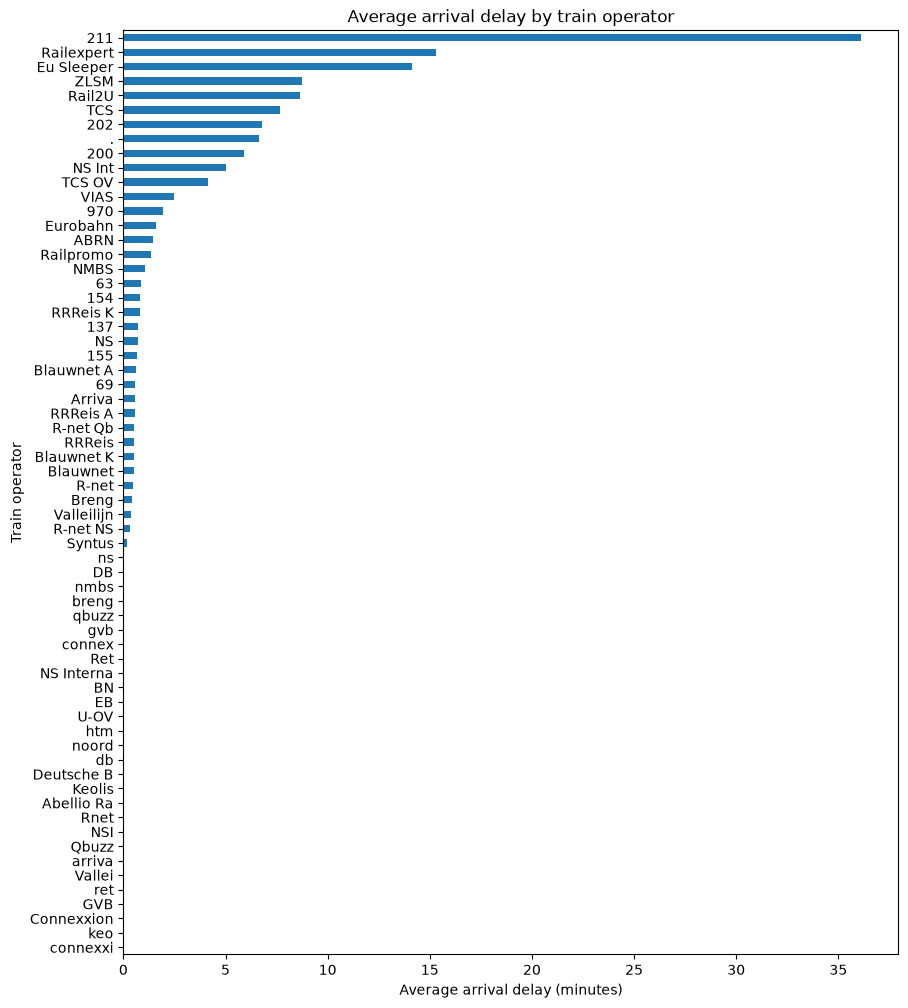

In [37]:
ax = delays_df.plot(
    kind="barh",
    x="company",
    y="avg_arrival_delay",
    figsize=(10, 12),
    legend=False,
    xlabel="Average arrival delay (minutes)",
    ylabel="Train operator",
    title="Average arrival delay by train operator",
)
ax.invert_yaxis()

How many services were disrupted in different years? Make a line plot.

In [38]:
disruptions_df = db.sql("""
SELECT
    YEAR(start_time) AS year,
    COUNT(*) AS n_disruptions
FROM postgres_db.disruptions
GROUP BY year
ORDER BY year
""").df()

disruptions_df.head()

,year,n_disruptions
0,2011,1846
1,2012,2074
2,2013,2312
3,2014,2484
4,2015,2947


(0.0, 6144.7)

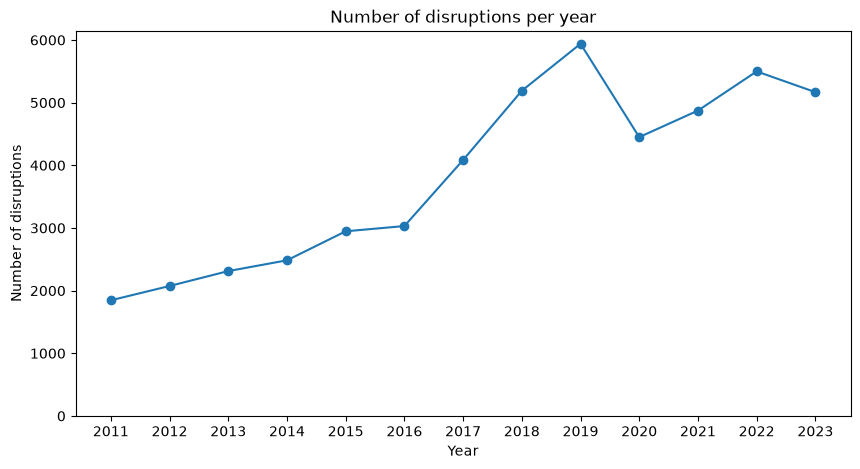

In [39]:
ax = disruptions_df.plot(
    kind="line",
    x="year",
    y="n_disruptions",
    marker="o",
    legend=False,
    figsize=(10, 5),
    xlabel="Year",
    ylabel="Number of disruptions",
    title="Number of disruptions per year",
)
ax.set_xticks(disruptions_df["year"])
ax.set_ylim(bottom=0)

What fraction of all services were cancelled (`Service:Completely cancelled`) in different years? Make a line plot.

In [40]:
# One row per service, then the share of completely cancelled services per year
cancelled_services_df = db.sql("""
WITH one_row_per_service AS (
    SELECT DISTINCT
        "Service:RDT-ID" AS service_id,
        YEAR("Service:Date") AS year,
        "Service:Completely cancelled" AS cancelled
    FROM services
)

SELECT
    year,
    COUNT(*) AS n_services,
    COUNT(*) FILTER (WHERE cancelled) AS n_cancelled,
    n_cancelled / n_services AS fraction_cancelled
FROM one_row_per_service
GROUP BY year
ORDER BY year
""").df()

(0.0, 0.09024884343462913)

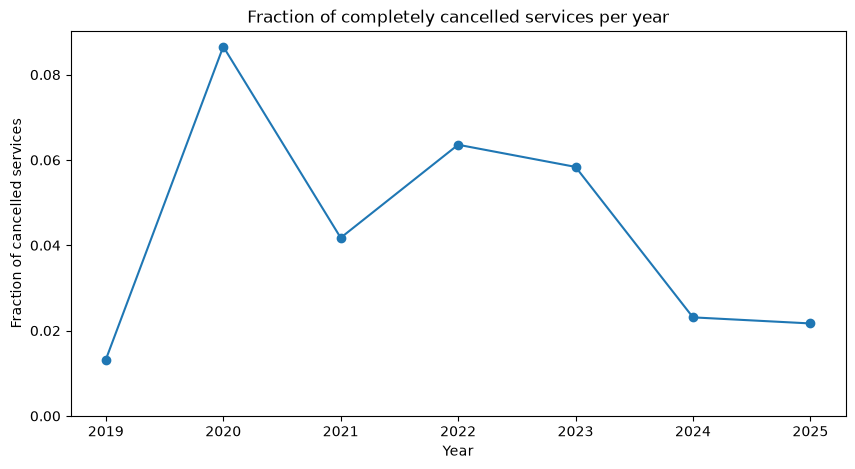

In [41]:
ax = cancelled_services_df.plot(
    kind="line",
    x="year",
    y="fraction_cancelled",
    marker="o",
    legend=False,
    figsize=(10, 5),
    xlabel="Year",
    ylabel="Fraction of cancelled services",
    title="Fraction of completely cancelled services per year",
)
ax.set_xticks(cancelled_services_df["year"])
ax.set_ylim(bottom=0)

### Adding service lengths informations

In [43]:
db.sql("""
SET memory_limit = '2GB';
SET temp_directory = 'db/tmp';
SET preserve_insertion_order = false;
""")

db.sql("""
CREATE OR REPLACE TABLE station_connections AS
WITH

next_stops AS (
    SELECT
        "Service:RDT-ID",
        "Stop:Station code" AS start_station_code,
        LEAD("Stop:Station code") OVER (
            PARTITION BY "Service:RDT-ID"
            ORDER BY "Stop:Departure time" NULLS LAST
        ) AS end_station_code
    FROM services
),

unique_pairs AS (
    SELECT
        start_station_code,
        end_station_code,
        MIN("Service:RDT-ID") AS "Service:RDT-ID"
    FROM next_stops
    WHERE end_station_code IS NOT NULL
    GROUP BY start_station_code, end_station_code
)

SELECT
    p."Service:RDT-ID",
    p.start_station_code,
    p.end_station_code,
    d.distance
FROM unique_pairs AS p
LEFT JOIN distances_long AS d
    ON d.station = p.start_station_code
    AND d.other_station = p.end_station_code
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [45]:
db.sql("SELECT * FROM station_connections LIMIT 5").show()


┌────────────────┬────────────────────┬──────────────────┬──────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ distance │
│     int64      │      varchar       │     varchar      │  int64   │
├────────────────┼────────────────────┼──────────────────┼──────────┤
│         738877 │ ZL                 │ MP               │       28 │
│         738846 │ UT                 │ HT               │       48 │
│         738949 │ AHZ                │ AH               │        8 │
│         738952 │ BMN                │ ZP               │        7 │
│         738846 │ BKG                │ HKS              │        4 │
└────────────────┴────────────────────┴──────────────────┴──────────┘



What is the largest distance between a pair of stations?

In [48]:
db.sql("""
SELECT
    c.start_station_code,
    c.end_station_code,
    s1.name_long AS start_station,
    s2.name_long AS end_station,
    c.distance
FROM station_connections AS c
LEFT JOIN stations AS s1 ON s1.code = c.start_station_code
LEFT JOIN stations AS s2 ON s2.code = c.end_station_code
WHERE c.distance IS NOT NULL
ORDER BY c.distance DESC
LIMIT 1
""")

┌────────────────────┬──────────────────┬───────────────┬─────────────┬──────────┐
│ start_station_code │ end_station_code │ start_station │ end_station │ distance │
│      varchar       │     varchar      │    varchar    │   varchar   │  int64   │
├────────────────────┼──────────────────┼───────────────┼─────────────┼──────────┤
│ STV                │ VS               │ Stavoren      │ Vlissingen  │      421 │
└────────────────────┴──────────────────┴───────────────┴─────────────┴──────────┘

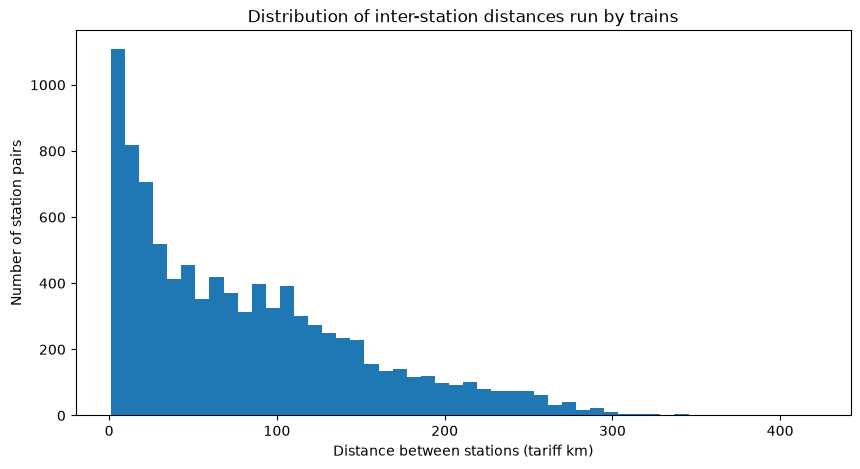

In [ ]:
distances_df = db.sql("""
SELECT distance
FROM station_connections
WHERE distance IS NOT NULL
""").df()

ax = distances_df["distance"].plot(
    kind="hist",
    bins=50,
    figsize=(10, 5),
    xlabel="Distance between stations (km)",
    title="Distribution of inter-station distances run by trains",
)
ax.set_ylabel("Number of station pairs")